# 05 · N-grams: bringing back word order

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-nlp-course/blob/main/notebooks/05_ngrams.ipynb)

*Practical NLP — a hands-on course in classical natural language processing · Notebook 5 of 12*

Bag-of-Words and TF-IDF treat a document as an unordered bag: *"the dog bit the man"* and *"the man bit the
dog"* get the same vector, and *"not good"* looks like *"good"*. **N-grams** — sequences of $n$ consecutive
tokens — put back some local word order. In this notebook we extract and count n-grams by hand, find
meaningful phrases (*collocations*), measure the price we pay in vocabulary size and sparsity, check when
n-grams actually help a classifier, and build a tiny **bigram language model**.

### Learning objectives
By the end of this notebook you will be able to:
1. Extract unigrams, bigrams and trigrams by hand and with NLTK / scikit-learn.
2. Count n-grams in a real corpus and find collocations with pointwise mutual information (PMI).
3. Quantify the **sparsity trade-off**: how vocabulary size and unseen n-grams explode as $n$ grows.
4. Use `ngram_range` in `CountVectorizer`/`TfidfVectorizer` and judge when n-grams help.
5. Estimate a bigram language model, generate text with it and explain why smoothing is needed.

## 0 · Setup

In [1]:
# Setup — works in Google Colab and locally.
# In Colab: installs missing packages and clones the course repo (for its cached data).
# Locally / in CI: uses the files already in data/ (NLP_OFFLINE=1 forbids any download).
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nltk>=3.9", "scikit-learn"], check=True)
    if not Path("practical-nlp-course").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-nlp-course.git"], check=True)
    os.chdir("practical-nlp-course/notebooks")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import nlp_course
nlp_course.setup_nltk()

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DOCS = ROOT / "docs"
DOCS.mkdir(exist_ok=True)
print("Offline mode:", nlp_course.OFFLINE)
print("Cached data:", sorted(p.name for p in (ROOT / "data").iterdir() if p.suffix in {".gz", ".json"}))

Offline mode: True
Cached data: ['20newsgroups_4cat.csv.gz', 'provenance.json', 'sms_spam.csv.gz']


In [2]:
from collections import Counter, defaultdict
import nltk
from nltk.util import ngrams
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

## 1 · What is an n-gram?
An **n-gram** is a run of $n$ consecutive tokens: $n=1$ **unigrams** (single words), $n=2$ **bigrams**,
$n=3$ **trigrams**. A sequence of $L$ tokens contains $L-n+1$ n-grams. Extracting them takes one line of
Python: zip the token list with shifted copies of itself.

In [3]:
def make_ngrams(tokens, n):
    return list(zip(*[tokens[i:] for i in range(n)]))

sentence = "the rocket reached orbit after the launch".split()
for n in (1, 2, 3):
    grams = make_ngrams(sentence, n)
    print(f"n={n}: {len(grams)} n-grams (L - n + 1 = {len(sentence)} - {n} + 1)")
    print("     ", [" ".join(g) for g in grams])

n=1: 7 n-grams (L - n + 1 = 7 - 1 + 1)
      ['the', 'rocket', 'reached', 'orbit', 'after', 'the', 'launch']
n=2: 6 n-grams (L - n + 1 = 7 - 2 + 1)
      ['the rocket', 'rocket reached', 'reached orbit', 'orbit after', 'after the', 'the launch']
n=3: 5 n-grams (L - n + 1 = 7 - 3 + 1)
      ['the rocket reached', 'rocket reached orbit', 'reached orbit after', 'orbit after the', 'after the launch']


In [4]:
assert make_ngrams(sentence, 3) == list(ngrams(sentence, 3))
print("NLTK's ngrams() gives the same trigrams.")

NLTK's ngrams() gives the same trigrams.


### N-grams restore (some) word order
With unigrams the two sentences below are indistinguishable; with bigrams they are not.

In [5]:
a, b = "the dog bit the man".split(), "the man bit the dog".split()
for n in (1, 2):
    ca, cb = Counter(make_ngrams(a, n)), Counter(make_ngrams(b, n))
    print(f"n={n}: identical bags? {ca == cb}")
    if n == 2:
        print("   only in a:", [" ".join(g) for g in ca - cb], "| only in b:", [" ".join(g) for g in cb - ca])

n=1: identical bags? True
n=2: identical bags? False
   only in a: ['dog bit'] | only in b: ['man bit']


The same happens with negation: in *"the movie was not good"* the bigram *not good* carries the meaning,
while the unigram *good* alone suggests the opposite. (Note that our default `preprocess()` drops *not* as a
stopword — pass `keep={"not", "no"}` when negation matters.)

## 2 · Counting n-grams on real text
For phrases we keep **every** word: stopwords such as *of* and *the* are part of most English phrases. We use
`preprocess(..., remove_stopwords=False, normalize=None)` — cleaned, lower-cased tokens in their original
order.

In [6]:
df = nlp_course.load_newsgroups()
train = df[df["subset"] == "train"].reset_index(drop=True)
test = df[df["subset"] == "test"].reset_index(drop=True)
tok = lambda t: nlp_course.preprocess(t, remove_stopwords=False, normalize=None)
train_tokens = [tok(t) for t in train["text"]]
test_tokens = [tok(t) for t in test["text"]]
print(f"training tokens: {sum(map(len, train_tokens)):,}")

counts = {n: Counter(g for d in train_tokens for g in make_ngrams(d, n)) for n in (1, 2, 3)}
pd.DataFrame({f"top {name}": [f"{' '.join(g)} ({c})" for g, c in counts[n].most_common(10)]
              for n, name in [(1, "unigrams"), (2, "bigrams"), (3, "trigrams")]})

training tokens: 385,113


,top unigrams,top bigrams,top trigrams
0,the (21081),of the (2330),one of the (128)
1,to (10728),in the (1673),be able to (104)
2,of (9228),to the (928),the united states (88)
3,and (8760),on the (890),some of the (79)
4,in (6269),for the (724),as well as (76)
5,is (5647),to be (690),part of the (74)
6,that (5614),that the (580),going to be (71)
7,it (4531),and the (569),you want to (69)
8,for (4339),it is (534),it would be (65)
9,you (3429),if you (533),there is no (65)


The most frequent n-grams are made of function words (*of the*, *in the*, *one of the*). Frequency alone
does not find interesting phrases — but a few real expressions already appear among the trigrams, such as
*the united states*.

### Content bigrams
If we drop bigrams that contain a stopword, the top of the list becomes topical.

In [7]:
stops = set(nltk.corpus.stopwords.words("english"))
content = Counter({g: c for g, c in counts[2].items() if not (set(g) & stops)})
top_b = content.most_common(15)
pd.DataFrame(top_b, columns=["bigram", "count"]).assign(bigram=lambda d: d["bigram"].str.join(" "))

,bigram,count
0,mr stephanopoulos,341
1,last year,126
2,ms myers,117
3,new york,109
4,united states,101
5,anonymous ftp,69
6,space station,68
7,space shuttle,68
8,los angeles,67
9,white house,64


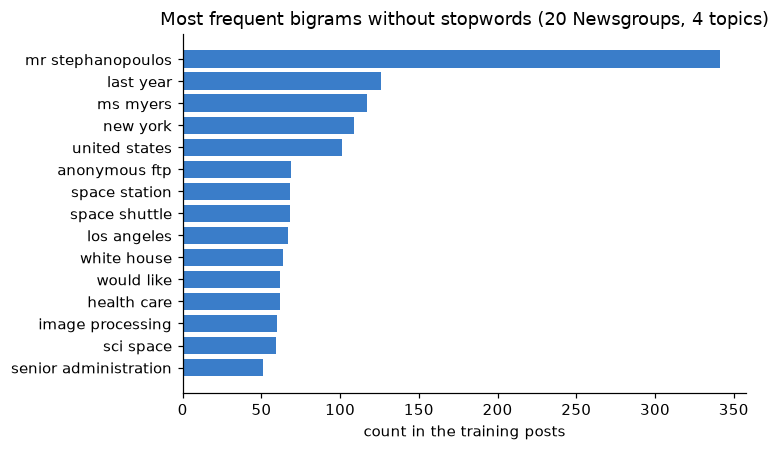

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.2))
labels = [" ".join(g) for g, _ in top_b][::-1]
ax.barh(labels, [c for _, c in top_b][::-1], color="#3a7dc9")
ax.set_xlabel("count in the training posts")
ax.set_title("Most frequent bigrams without stopwords (20 Newsgroups, 4 topics)")
plt.tight_layout(); plt.savefig(DOCS / "05_top_bigrams.png", bbox_inches="tight"); plt.show()

### Collocations with pointwise mutual information (PMI)
A **collocation** is a pair of words that occur together more often than chance (*space station*, *new
york*). PMI compares the observed probability of the bigram with what we would expect if the two words
were independent:

$$\mathrm{PMI}(w_1, w_2) = \log_2 \frac{P(w_1 w_2)}{P(w_1)\,P(w_2)}$$

PMI loves rare pairs (two words seen once, together, get a huge score), so we keep only bigrams seen at
least 10 times. First by hand, then with NLTK's `BigramCollocationFinder`.

In [9]:
n_uni = sum(counts[1].values())
n_bi = sum(counts[2].values())
def pmi(g):
    return np.log2((counts[2][g] / n_bi) / ((counts[1][(g[0],)] / n_uni) * (counts[1][(g[1],)] / n_uni)))

frequent = [g for g, c in counts[2].items() if c >= 10]
by_pmi = sorted(frequent, key=pmi, reverse=True)[:12]
pd.DataFrame({"bigram": [" ".join(g) for g in by_pmi], "count": [counts[2][g] for g in by_pmi],
              "PMI (by hand)": [round(pmi(g), 2) for g in by_pmi]})

,bigram,count,PMI (by hand)
0,funet fi,11,14.24
1,wuarchive wustl,10,14.18
2,physicist dewey,12,14.09
3,ics uci,22,14.04
4,arms embargo,13,14.03
5,mary shafer,18,13.86
6,xxxx xxxx,22,13.85
7,export lcs,10,13.78
8,vertex vertex,17,13.73
9,incoming geode,17,13.73


In [10]:
from nltk.collocations import BigramCollocationFinder, BigramAssocMeasures
finder = BigramCollocationFinder.from_documents(train_tokens)
finder.apply_freq_filter(10)
nltk_top = finder.nbest(BigramAssocMeasures.pmi, 12)
print("NLTK top-12 by PMI:", [" ".join(g) for g in nltk_top])
print("same set as ours:", set(nltk_top) == set(by_pmi))

NLTK top-12 by PMI: ['funet fi', 'wuarchive wustl', 'physicist dewey', 'ics uci', 'arms embargo', 'mary shafer', 'xxxx xxxx', 'export lcs', 'vertex vertex', 'incoming geode', 'eddie murray', 'lcs mit']
same set as ours: True


PMI surfaces people's names (*mary shafer*, *eddie murray*), internet host names (*funet fi*, *ics uci*,
*lcs mit*) and fixed expressions (*arms embargo*) — multi-word units that a unigram model splits apart. It
also surfaces artefacts such as *xxxx xxxx* or *vertex vertex* from repeated data: PMI finds *strongly
associated* pairs, not necessarily *meaningful* ones. (NLTK counts bigrams *within* each document, as we did,
so both lists agree.)

## 3 · The price of n-grams: vocabulary explosion and sparsity
Every extra word of context multiplies the number of possible combinations. Let us measure, for
$n = 1, 2, 3$:
- the number of **distinct** n-grams in the training posts,
- the share of them seen **only once** (hapaxes),
- the share of n-gram occurrences in the **test** posts that never appeared in training.

In [11]:
rows = []
for n in (1, 2, 3):
    c = counts[n]
    test_grams = [g for d in test_tokens for g in make_ngrams(d, n)]
    unseen = sum(g not in c for g in test_grams) / len(test_grams)
    rows.append({"n": n, "distinct n-grams": len(c),
                 "seen once": f"{sum(v == 1 for v in c.values()) / len(c):.1%}",
                 "unseen in test": f"{unseen:.1%}", "_unseen": unseen,
                 "_once": sum(v == 1 for v in c.values()) / len(c)})
stats = pd.DataFrame(rows).set_index("n")
stats.drop(columns=["_unseen", "_once"])

,distinct n-grams,seen once,unseen in test
n,,,
1,23195,42.5%,3.2%
2,193226,77.0%,37.2%
3,320036,90.6%,69.9%


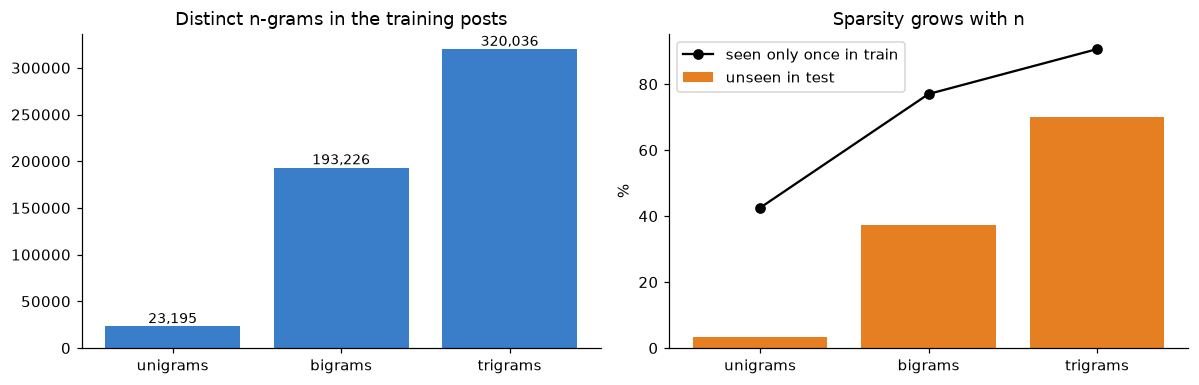

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(["unigrams", "bigrams", "trigrams"], stats["distinct n-grams"], color="#3a7dc9")
axes[0].set_title("Distinct n-grams in the training posts")
for x, v in enumerate(stats["distinct n-grams"]):
    axes[0].text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
axes[1].bar(["unigrams", "bigrams", "trigrams"], 100 * stats["_unseen"], color="#e67e22", label="unseen in test")
axes[1].plot(["unigrams", "bigrams", "trigrams"], 100 * stats["_once"], "ko-", label="seen only once in train")
axes[1].set_ylabel("%"); axes[1].set_title("Sparsity grows with n"); axes[1].legend()
plt.tight_layout(); plt.savefig(DOCS / "05_ngram_sparsity.png", bbox_inches="tight"); plt.show()

Going from unigrams to trigrams multiplies the number of distinct features by more than 13, and most
trigrams are seen only once. Worse, about 70% of the trigram occurrences in the test posts never appeared
in training, against 3% for single words. Longer n-grams are more *specific*, but also far more *sparse*:
there is never enough data to see most of them. This is the central trade-off of n-gram models.

## 4 · N-grams in scikit-learn: `ngram_range`
`CountVectorizer` and `TfidfVectorizer` build n-grams for you with `ngram_range=(min_n, max_n)`.
`(1, 2)` means unigrams **and** bigrams. Here the vectorizer uses its own tokenizer on the raw text.

In [13]:
demo = ["the rocket reached orbit", "the pitcher threw the ball"]
cv12 = CountVectorizer(ngram_range=(1, 2)).fit(demo)
print(list(cv12.get_feature_names_out()))

['ball', 'orbit', 'pitcher', 'pitcher threw', 'reached', 'reached orbit', 'rocket', 'rocket reached', 'the', 'the ball', 'the pitcher', 'the rocket', 'threw', 'threw the']


In [14]:
rows = []
for ng in [(1, 1), (1, 2), (1, 3), (2, 2), (3, 3)]:
    for min_df in (1, 2):
        X = CountVectorizer(ngram_range=ng, min_df=min_df).fit_transform(train["text"])
        rows.append({"ngram_range": str(ng), "min_df": min_df, "features": X.shape[1],
                     "density": f"{X.nnz / (X.shape[0] * X.shape[1]):.4%}"})
pd.DataFrame(rows).set_index(["ngram_range", "min_df"])

features  density
ngram_range min_df                   
(1, 1)      1          26876  0.3477%
            2          13068  0.6680%
(1, 2)      1         234591  0.1069%
            2          52633  0.3220%
(1, 3)      1         570579  0.0740%
            2          78122  0.2590%
(2, 2)      1         207715  0.0757%
            2          39565  0.2077%
(3, 3)      1         335988  0.0511%
            2          25489  0.1289%

`min_df=2` is almost mandatory with n-grams: it removes every n-gram seen in a single document, which
cuts the feature count several-fold while keeping the n-grams that can generalise.

### Do n-grams help a classifier?
A quick preview of notebook 10: a logistic-regression classifier on TF-IDF features, with unigrams only vs
unigrams + bigrams, on our two datasets.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

sms = nlp_course.load_sms()
sms_tr, sms_te = train_test_split(sms, test_size=0.3, random_state=0, stratify=sms["label"])
results = []
for ng in [(1, 1), (1, 2)]:
    v = TfidfVectorizer(ngram_range=ng, min_df=2, sublinear_tf=True)
    clf = LogisticRegression(max_iter=2000, C=10).fit(v.fit_transform(train["text"]), train["category"])
    acc = accuracy_score(test["category"], clf.predict(v.transform(test["text"])))
    v2 = TfidfVectorizer(ngram_range=ng, min_df=2)
    clf2 = LogisticRegression(max_iter=2000, C=10).fit(v2.fit_transform(sms_tr["text"]), sms_tr["label"])
    f1 = f1_score(sms_te["label"], clf2.predict(v2.transform(sms_te["text"])), pos_label="spam")
    results.append({"ngram_range": str(ng), "newsgroups: features": len(v.vocabulary_),
                    "newsgroups: test accuracy": round(acc, 3),
                    "SMS: features": len(v2.vocabulary_), "SMS: spam F1": round(f1, 3)})
pd.DataFrame(results).set_index("ngram_range")

,newsgroups: features,newsgroups: test accuracy,SMS: features,SMS: spam F1
ngram_range,,,,
"(1, 1)",13068,0.856,3294,0.915
"(1, 2)",52633,0.854,10768,0.931


N-grams are not a free win. On the SMS data, bigrams such as *please call* or *to claim* (see exercise 2) add useful
signal and the spam F1 improves (0.915 → 0.931). On the newsgroup topics, single words already identify the topic and the
four-fold larger bigram vocabulary brings no gain — the test accuracy even drops slightly. Always measure.

## 5 · A bigram language model
N-grams are also the basis of the classic **language model**, which assigns a probability to a sequence of
words. With the **Markov assumption** each word depends only on the previous one:

$$P(w_1 \dots w_L) \approx \prod_{i} P(w_i \mid w_{i-1}), \qquad
P(w_i \mid w_{i-1}) = \frac{\mathrm{count}(w_{i-1}\,w_i)}{\mathrm{count}(w_{i-1})}$$

This is the **maximum-likelihood estimate** (MLE). We train it on the `sci.space` training posts, adding
`<s>` and `</s>` markers for the start and end of each post.

In [16]:
space_docs = [d for d, c in zip(train_tokens, train["category"]) if c == "sci.space" and d]
bigram_counts = defaultdict(Counter)
for d in space_docs:
    seq = ["<s>"] + d + ["</s>"]
    for w1, w2 in zip(seq, seq[1:]):
        bigram_counts[w1][w2] += 1

def p_next(w1):
    total = sum(bigram_counts[w1].values())
    return {w2: c / total for w2, c in bigram_counts[w1].most_common()}

print(f"{len(space_docs)} sci.space posts, {len(bigram_counts):,} distinct context words")
for w in ["space", "the", "orbit"]:
    print(f"P(· | {w!r}):", {k: round(v, 3) for k, v in list(p_next(w).items())[:6]})

577 sci.space posts, 11,874 distinct context words
P(· | 'space'): {'station': 0.069, 'shuttle': 0.065, 'and': 0.03, 'news': 0.019, 'center': 0.018, 'program': 0.017}
P(· | 'the'): {'moon': 0.017, 'space': 0.016, 'first': 0.016, 'same': 0.01, 'earth': 0.007, 'sun': 0.007}
P(· | 'orbit'): {'the': 0.09, 'for': 0.035, 'and': 0.035, 'of': 0.035, 'on': 0.03, 'to': 0.03}


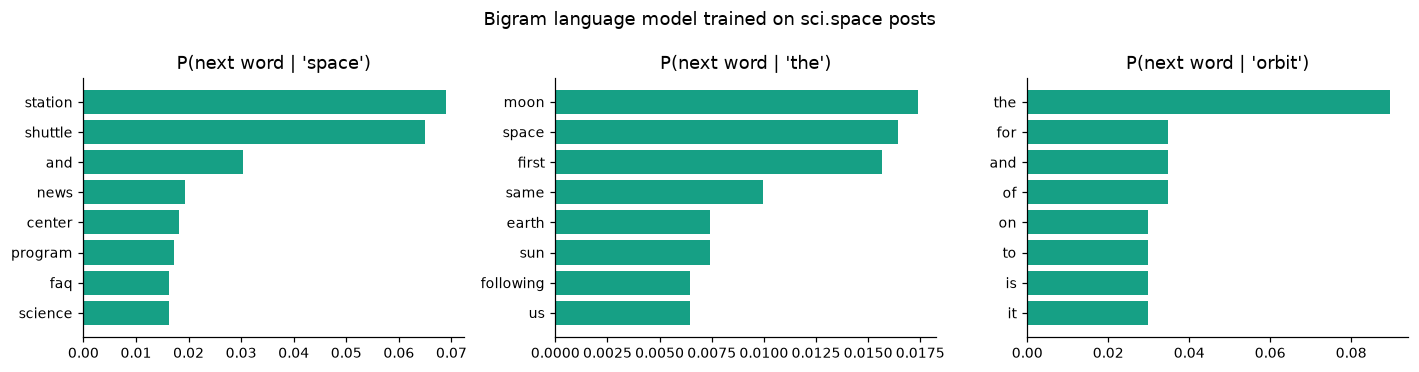

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, w in zip(axes, ["space", "the", "orbit"]):
    items = list(p_next(w).items())[:8][::-1]
    ax.barh([k for k, _ in items], [v for _, v in items], color="#16a085")
    ax.set_title(f"P(next word | '{w}')"); ax.tick_params(labelsize=9)
fig.suptitle("Bigram language model trained on sci.space posts")
plt.tight_layout(); plt.savefig(DOCS / "05_next_word.png", bbox_inches="tight"); plt.show()

### Generating text
Sampling one word at a time from $P(w_i \mid w_{i-1})$ produces text that is locally plausible — each pair
of neighbouring words is a real bigram — but has no global meaning.

In [18]:
rng = np.random.default_rng(42)
def generate(start="<s>", max_len=20):
    w, out = start, []
    for _ in range(max_len):
        nxt = p_next(w)
        w = rng.choice(list(nxt), p=list(nxt.values()))
        if w == "</s>":
            break
        out.append(w)
    return " ".join(out)

for _ in range(4):
    print("-", generate())

- hum do malfunction in the gummint could as well they will blow anything significant for space sales are affected it
- besides maybe lemur sometimes broadcast services fixed and are internal political marching orders of science data from other european coordination
- think mark my guess nothing you think the tiny world wide field an improved geostationary goes out but the nasa
- nope haven given was efficiently spent providing watt power for this option believe that the best to win can confirm


### The zero-probability problem and add-one smoothing
Under MLE, a bigram that never occurred in training gets probability **0**, so any sentence containing it
gets probability 0 — however reasonable it is. **Add-one (Laplace) smoothing** pretends every bigram was seen
once more than it was:

$$P_{\text{add-1}}(w_i \mid w_{i-1}) = \frac{\mathrm{count}(w_{i-1}\,w_i) + 1}{\mathrm{count}(w_{i-1}) + |V|}$$

In [19]:
V = len({w for d in space_docs for w in d} | {"</s>"})
def sentence_logprob(words, smooth=False):
    seq = ["<s>"] + words + ["</s>"]
    lp = 0.0
    for w1, w2 in zip(seq, seq[1:]):
        c12, c1 = bigram_counts[w1][w2], sum(bigram_counts[w1].values())
        p = (c12 + 1) / (c1 + V) if smooth else (c12 / c1 if c1 else 0.0)
        if p == 0:
            return -np.inf
        lp += np.log(p)
    return lp

for s in ["the space station", "the space shuttle", "the rocket station"]:
    words = s.split()
    unseen = [f"{a} {b}" for a, b in zip(["<s>"] + words, words + ["</s>"]) if bigram_counts[a][b] == 0]
    print(f"{s!r:24} MLE log P = {sentence_logprob(words):8.2f}   add-one log P = "
          f"{sentence_logprob(words, smooth=True):8.2f}   unseen bigrams: {unseen}")

'the space station'      MLE log P =   -13.55   add-one log P =   -24.47   unseen bigrams: []
'the space shuttle'      MLE log P =     -inf   add-one log P =   -25.63   unseen bigrams: ['shuttle </s>']
'the rocket station'     MLE log P =     -inf   add-one log P =   -30.65   unseen bigrams: ['rocket station']


With MLE, any sentence containing a bigram never seen in training gets $\log P = -\infty$ — even the
perfectly reasonable *the space shuttle*, simply because no training post ended with *shuttle*. Add-one
smoothing gives it a small but non-zero probability, so sentences can still be compared. Add-one is the
simplest fix; real n-gram models use better schemes (Kneser–Ney, back-off), and neural language models
replace counting altogether.

## 6 · Character n-grams
N-grams can be made of **characters** instead of words. `analyzer="char_wb"` builds character n-grams
inside word boundaries. They are robust to typos and inflections: a misspelt word still shares most of its
character trigrams with the correct spelling.

In [20]:
cv_char = CountVectorizer(analyzer="char_wb", ngram_range=(3, 3))
cv_char.fit(["sounds like", "sounds liek"])
X_char = cv_char.transform(["sounds like", "sounds liek"]).toarray()
feat = cv_char.get_feature_names_out()
print("character trigrams:", list(feat))
shared = int(np.minimum(X_char[0], X_char[1]).sum())
print(f"shared trigrams: {shared} of {X_char[0].sum()}")
cv_word = CountVectorizer().fit(["sounds like", "sounds liek"])
Xw = cv_word.transform(["sounds like", "sounds liek"]).toarray()
print(f"shared words:    {int(np.minimum(Xw[0], Xw[1]).sum())} of {Xw[0].sum()}")

character trigrams: [' li', ' so', 'ds ', 'ek ', 'iek', 'ike', 'ke ', 'lie', 'lik', 'nds', 'oun', 'sou', 'und']
shared trigrams: 7 of 10
shared words:    1 of 2


## 7 · Exercises

**Exercise 1.** Using `counts`, list the 10 most frequent **trigrams** in the `rec.sport.baseball` training
posts that contain no stopword.

In [21]:
# your code here

<details>
<summary><b>Show solution</b></summary>

```python
base = Counter(g for d, c in zip(train_tokens, train["category"]) if c == "rec.sport.baseball"
               for g in make_ngrams(d, 3) if not (set(g) & stops))
[(" ".join(g), c) for g, c in base.most_common(10)]
```
</details>

In [22]:
base = Counter(g for d, c in zip(train_tokens, train["category"]) if c == "rec.sport.baseball"
               for g in make_ngrams(d, 3) if not (set(g) & stops))
[(" ".join(g), c) for g, c in base.most_common(10)]

[('cubs suck cubs', 32),
 ('suck cubs suck', 30),
 ('boston red sox', 11),
 ('games era saves', 11),
 ('toronto blue jays', 10),
 ('st louis cardinals', 10),
 ('chicago white sox', 9),
 ('new york yankees', 9),
 ('kansas city royals', 9),
 ('new york mets', 9)]

**Exercise 2.** With `CountVectorizer(ngram_range=(2, 2), min_df=5)` on the SMS messages, find the 10
bigrams with the highest count among **spam** messages.

In [23]:
# your code here

<details>
<summary><b>Show solution</b></summary>

Phrases such as *to claim*, *please call* or *your mobile* are strong spam markers that single words only partly capture.

```python
cvb = CountVectorizer(ngram_range=(2, 2), min_df=5)
Xs = cvb.fit_transform(sms["text"])
spam_counts = np.asarray(Xs[(sms["label"] == "spam").to_numpy()].sum(axis=0)).ravel()
names = cvb.get_feature_names_out()
[(names[j], int(spam_counts[j])) for j in spam_counts.argsort()[::-1][:10]]
```
</details>

In [24]:
cvb = CountVectorizer(ngram_range=(2, 2), min_df=5)
Xs = cvb.fit_transform(sms["text"])
spam_counts = np.asarray(Xs[(sms["label"] == "spam").to_numpy()].sum(axis=0)).ravel()
names = cvb.get_feature_names_out()
[(names[j], int(spam_counts[j])) for j in spam_counts.argsort()[::-1][:10]]

[('you have', 73),
 ('have won', 54),
 ('your mobile', 50),
 ('co uk', 49),
 ('to claim', 47),
 ('please call', 46),
 ('this is', 41),
 ('to contact', 37),
 ('you are', 36),
 ('stop to', 29)]

**Exercise 3.** Build a **trigram** version of the language model (context = the two previous words) on
the same `sci.space` posts. How many distinct two-word contexts are there, and what fraction of them is
followed by a single possible next word in the training data? What does this say about sparsity?

In [25]:
# your code here

<details>
<summary><b>Show solution</b></summary>

Most two-word contexts were seen with a single continuation, so an MLE trigram model mostly memorises the training text.

```python
tri = defaultdict(Counter)
for d in space_docs:
    seq = ["<s>", "<s>"] + d + ["</s>"]
    for w1, w2, w3 in zip(seq, seq[1:], seq[2:]):
        tri[(w1, w2)][w3] += 1
single = sum(len(c) == 1 for c in tri.values()) / len(tri)
print(f"{len(tri):,} two-word contexts; {single:.1%} of them have only one observed continuation")
```
</details>

In [26]:
tri = defaultdict(Counter)
for d in space_docs:
    seq = ["<s>", "<s>"] + d + ["</s>"]
    for w1, w2, w3 in zip(seq, seq[1:], seq[2:]):
        tri[(w1, w2)][w3] += 1
single = sum(len(c) == 1 for c in tri.values()) / len(tri)
print(f"{len(tri):,} two-word contexts; {single:.1%} of them have only one observed continuation")

68,616 two-word contexts; 84.4% of them have only one observed continuation


## Summary
- An **n-gram** is a run of $n$ consecutive tokens; bigrams and trigrams restore local word order
  (*dog bit* ≠ *bit dog*, *not good* ≠ *good*).
- Frequent n-grams are dominated by function words; removing stopwords or ranking by **PMI** reveals
  topical phrases and collocations.
- Larger $n$ means **many more features** and **far more sparsity**: most trigrams are seen once, and most
  test trigrams were never seen in training. Use `min_df`.
- In scikit-learn, `ngram_range=(1, 2)` adds bigrams; whether that helps depends on the task — measure it.
- A **bigram language model** estimates $P(w_i \mid w_{i-1})$ from counts; it needs **smoothing** to give
  unseen bigrams a non-zero probability.

**Next:** [06 · Document similarity](06_document_similarity.ipynb) — comparing documents with cosine similarity.